In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("Computer Vision Module Ready!")
print("OpenCV:", cv2.__version__)

Computer Vision Module Ready!
OpenCV: 5.1.0


In [5]:
import cv2
import os

image_folder = "../data/sample_ads"

image_files = {
    "Product": "product_advertisement.jpg",
    "Fashion": "fashion_advertisement.jpg",
    "Food": "food_advertisement.jpg"
}

images = {}

for category, filename in image_files.items():
    path = os.path.join(image_folder, filename)

    image = cv2.imread(path)

    if image is None:
        print(f"Could not load: {filename}")
    else:
        images[category] = image
        height, width, channels = image.shape

        print(f"\n{category} Advertisement")
        print("Width:", width)
        print("Height:", height)
        print("Channels:", channels)

print("\nTotal images loaded:", len(images))


Product Advertisement
Width: 416
Height: 740
Channels: 3

Fashion Advertisement
Width: 736
Height: 970
Channels: 3

Food Advertisement
Width: 736
Height: 1307
Channels: 3

Total images loaded: 3


In [6]:
image_analysis = []

for category, image in images.items():

    # Convert BGR to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Image dimensions
    height, width = image.shape[:2]

    # Brightness
    brightness = np.mean(gray)

    # Contrast
    contrast = np.std(gray)

    # Resolution
    resolution = width * height

    image_analysis.append({
        "Category": category,
        "Width": width,
        "Height": height,
        "Resolution": resolution,
        "Brightness": round(brightness, 2),
        "Contrast": round(contrast, 2)
    })

analysis_df = pd.DataFrame(image_analysis)

display(analysis_df)

,Category,Width,Height,Resolution,Brightness,Contrast
0,Product,416,740,307840,64.66,60.99
1,Fashion,736,970,713920,181.28,67.05
2,Food,736,1307,961952,167.99,65.21


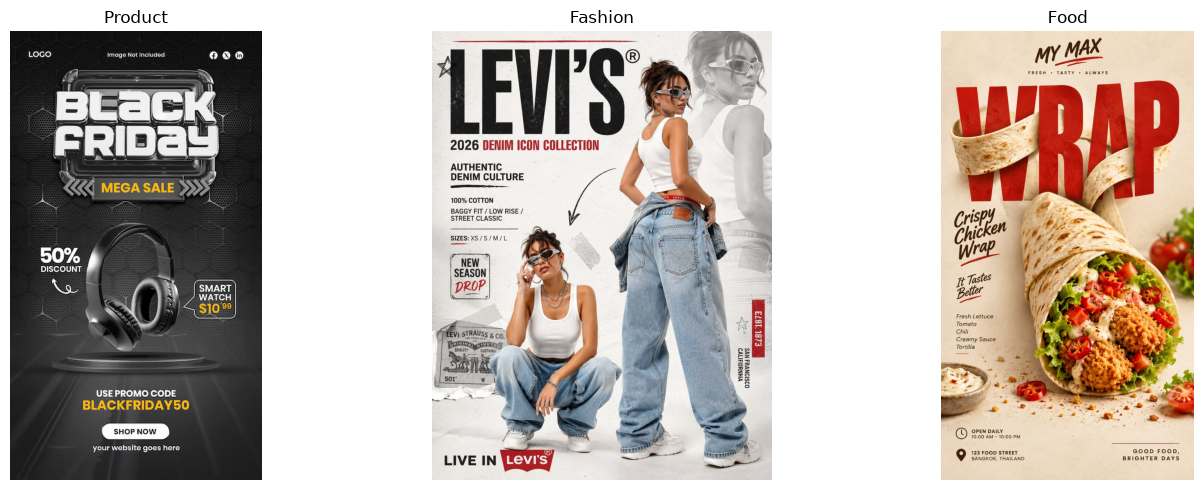

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (category, image) in zip(axes, images.items()):

    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(rgb_image)
    ax.set_title(category)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.cluster import KMeans

print("KMeans imported successfully!")

KMeans imported successfully!


In [12]:
for category, image in images.items():

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (150, 150))

    pixels = resized.reshape(-1, 3)

    kmeans = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(pixels)

    colors = kmeans.cluster_centers_.astype(int)

    counts = np.bincount(labels)
    percentages = counts / len(labels) * 100

    print("\n", category)

    for color, percentage in zip(colors, percentages):
        print(f"RGB: {tuple(color)} | {percentage:.2f}%")


 Product
RGB: (np.int64(158), np.int64(148), np.int64(122)) | 5.32%
RGB: (np.int64(48), np.int64(48), np.int64(48)) | 34.12%
RGB: (np.int64(236), np.int64(236), np.int64(236)) | 7.75%
RGB: (np.int64(24), np.int64(24), np.int64(24)) | 37.07%
RGB: (np.int64(78), np.int64(78), np.int64(77)) | 15.74%

 Fashion
RGB: (np.int64(238), np.int64(235), np.int64(231)) | 44.51%
RGB: (np.int64(127), np.int64(88), np.int64(80)) | 9.41%
RGB: (np.int64(149), np.int64(149), np.int64(153)) | 20.31%
RGB: (np.int64(34), np.int64(33), np.int64(33)) | 9.34%
RGB: (np.int64(199), np.int64(196), np.int64(193)) | 16.44%

 Food
RGB: (np.int64(90), np.int64(50), np.int64(10)) | 7.92%
RGB: (np.int64(238), np.int64(218), np.int64(191)) | 49.36%
RGB: (np.int64(215), np.int64(174), np.int64(123)) | 14.79%
RGB: (np.int64(175), np.int64(124), np.int64(54)) | 11.71%
RGB: (np.int64(181), np.int64(31), np.int64(11)) | 16.23%


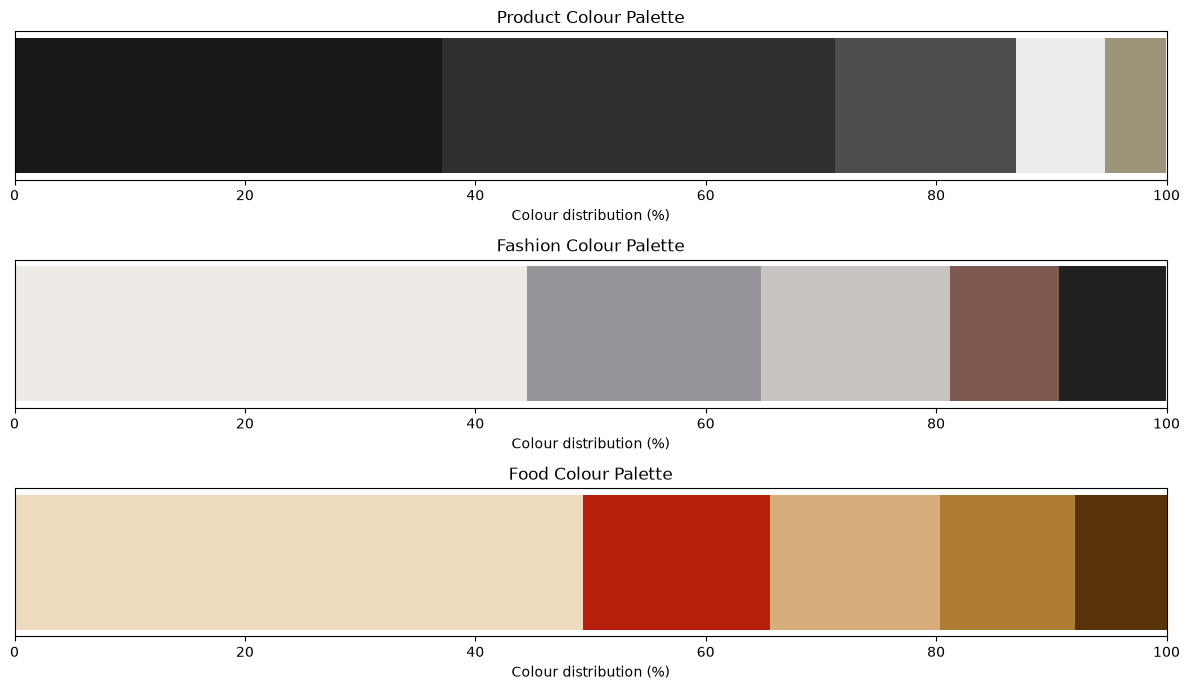

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))

for ax, (category, image) in zip(axes, images.items()):

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (150, 150))
    pixels = resized.reshape(-1, 3)

    kmeans = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(pixels)
    colors = kmeans.cluster_centers_.astype(int)

    counts = np.bincount(labels)
    percentages = counts / len(labels) * 100

    order = np.argsort(percentages)[::-1]

    for i, idx in enumerate(order):
        color = colors[idx] / 255

        ax.barh(
            0,
            percentages[idx],
            left=sum(percentages[order[:i]]),
            color=color,
            height=0.7
        )

    ax.set_xlim(0, 100)
    ax.set_yticks([])
    ax.set_title(category + " Colour Palette")
    ax.set_xlabel("Colour distribution (%)")

plt.tight_layout()
plt.show()

In [14]:
def calculate_design_score(image):

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    height, width = image.shape[:2]

    brightness = np.mean(gray)
    contrast = np.std(gray)
    resolution = width * height

    # Brightness score
    brightness_score = max(
        0, 100 - abs(brightness - 140) * 0.7
    )

    # Contrast score
    contrast_score = min(100, contrast * 1.5)

    # Resolution score
    resolution_score = min(
        100, (resolution / (1080 * 1920)) * 100
    )

    # Weighted overall score
    final_score = (
        brightness_score * 0.35 +
        contrast_score * 0.35 +
        resolution_score * 0.30
    )

    return {
        "Brightness Score": round(brightness_score, 2),
        "Contrast Score": round(contrast_score, 2),
        "Resolution Score": round(resolution_score, 2),
        "Design Score": round(final_score, 2)
    }

In [15]:
score_results = []

for category, image in images.items():

    scores = calculate_design_score(image)

    scores["Category"] = category

    score_results.append(scores)

score_df = pd.DataFrame(score_results)

display(score_df)

,Brightness Score,Contrast Score,Resolution Score,Design Score,Category
0,47.26,91.49,14.85,53.02,Product
1,71.10,100.00,34.43,70.22,Fashion
2,80.41,97.81,46.39,76.29,Food


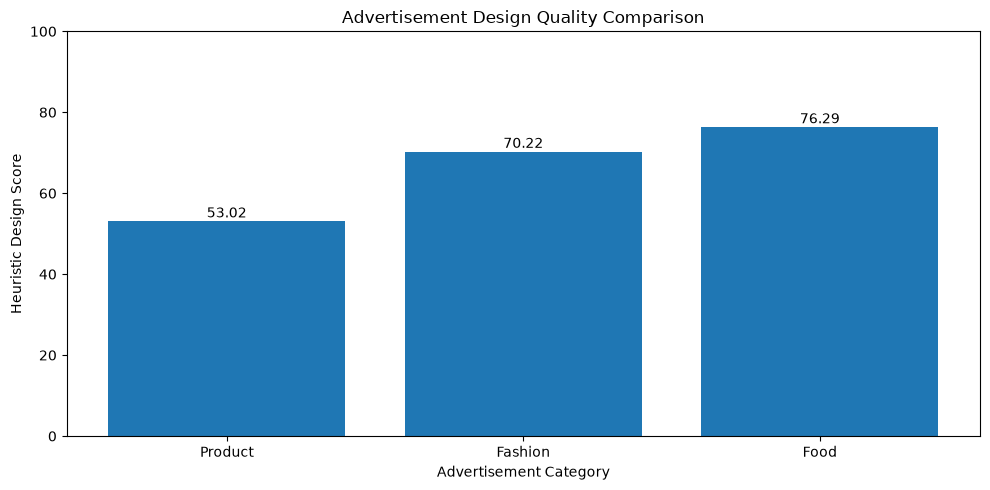

In [16]:
plt.figure(figsize=(10, 5))

plt.bar(
    score_df["Category"],
    score_df["Design Score"]
)

plt.title("Advertisement Design Quality Comparison")
plt.xlabel("Advertisement Category")
plt.ylabel("Heuristic Design Score")
plt.ylim(0, 100)

for i, score in enumerate(score_df["Design Score"]):
    plt.text(i, score + 1, str(score), ha="center")

plt.tight_layout()
plt.show()

In [19]:
from sklearn.cluster import KMeans

def calculate_color_diversity(image):

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (150, 150))

    pixels = resized.reshape(-1, 3)

    kmeans = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(pixels)

    counts = np.bincount(labels)
    percentages = counts / len(labels) * 100

    # Shannon entropy
    probabilities = percentages / 100
    entropy = -np.sum(
        probabilities * np.log2(probabilities + 1e-10)
    )

    # Normalize score to 0–100
    diversity_score = (entropy / np.log2(5)) * 100

    return round(diversity_score, 2)

In [20]:
diversity_results = []

for category, image in images.items():

    score = calculate_color_diversity(image)

    diversity_results.append({
        "Category": category,
        "Colour Diversity Score": score
    })

diversity_df = pd.DataFrame(diversity_results)

display(diversity_df)

,Category,Colour Diversity Score
0,Product,85.75
1,Fashion,88.52
2,Food,85.63


In [21]:
final_results = []

for category, image in images.items():

    scores = calculate_design_score(image)

    diversity = calculate_color_diversity(image)

    # Add colour diversity
    scores["Colour Diversity Score"] = diversity

    # Updated weighted score
    updated_score = (
        scores["Brightness Score"] * 0.25 +
        scores["Contrast Score"] * 0.25 +
        scores["Resolution Score"] * 0.25 +
        diversity * 0.25
    )

    scores["Updated Design Score"] = round(updated_score, 2)
    scores["Category"] = category

    final_results.append(scores)

final_design_df = pd.DataFrame(final_results)

display(final_design_df)

,Brightness Score,Contrast Score,Resolution Score,Design Score,Colour Diversity Score,Updated Design Score,Category
0,47.26,91.49,14.85,53.02,85.75,59.84,Product
1,71.10,100.00,34.43,70.22,88.52,73.51,Fashion
2,80.41,97.81,46.39,76.29,85.63,77.56,Food


In [22]:
try:
    saliency = cv2.saliency.StaticSaliencySpectralResidual_create()
    print("Saliency module available!")
except AttributeError:
    print("Saliency module not available.")

Saliency module not available.
